# 04. K-Means: pencarian k dan profiling

Satu model pada gabungan 20 triwulan historis menjaga makna label antarperiode. Label profil tidak diurutkan menjadi rendah/sedang/tinggi.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../03_eda/03_eda.ipynb) | [Berikutnya](../05_dbscan/05_dbscan.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Definisi evaluasi clustering](#s2)
- [3. Label, profil asli, dan proyeksi visual](#s3)
- [4. Pencarian k dan fitting historis](#s4)
- [5. Jalankan K-Means](#s5)
- [6. Penamaan dan interpretasi kelompok (setelah clustering)](#s6)
- [7. Tabel nama kelompok dan angka dasarnya](#s7)
- [8. Lihat elbow, evaluasi, dan cluster](#s8)

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_prepared, save_model_metadata

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Definisi evaluasi clustering

Silhouette dirata-rata dari tiga sampel acak, masing-masing maksimal 2.000 baris, untuk pemilihan parameter; SD sampel disimpan. DBI dihitung pada seluruh baris yang ditugaskan. Ini metrik internal, bukan akurasi.

In [2]:
def cluster_metrics(X, labels, sample_size=2000, seed=42):
    X, labels = np.asarray(X), np.asarray(labels)
    assigned = labels >= 0
    values, counts = np.unique(labels[assigned], return_counts=True)
    result = {"n_rows": len(labels), "n_clusters": len(values), "n_assigned": int(assigned.sum()),
              "noise_fraction": float((~assigned).mean()),
              "largest_cluster_fraction_assigned": float(counts.max()/counts.sum()) if len(counts) else np.nan,
              "smallest_cluster_size": int(counts.min()) if len(counts) else 0,
              "silhouette": np.nan, "davies_bouldin": np.nan, "silhouette_n": 0}
    if len(values) < 2 or assigned.sum() <= len(values):
        return result
    xx, yy = X[assigned], labels[assigned]
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(xx), min(sample_size, len(xx)), replace=False)
    observed = len(np.unique(yy[indices]))
    if 1 < observed < len(indices):
        result["silhouette"] = float(silhouette_score(xx[indices], yy[indices]))
        result["silhouette_n"] = len(indices)
    result["davies_bouldin"] = float(davies_bouldin_score(xx, yy))
    return result

<a id="s3"></a>
## 3. Label, profil asli, dan proyeksi visual

Centroid dipelajari di ruang fitur standar; profiling ditampilkan dalam satuan asli. PCA 2D hanya membantu melihat hasil, bukan ruang pelatihan atau peta geografis.

In [3]:
def full_labels(panel, train, labels, method):
    values = train[["row_id"]].copy()
    values["cluster"] = labels
    result = panel.loc[panel["split"].eq("train")].merge(values, on="row_id", how="left", validate="one_to_one")
    result["profile"] = result["state"]
    valid = result["cluster"].notna()
    result.loc[valid, "profile"] = result.loc[valid, "cluster"].astype(int).map(
        lambda n: "NOISE" if n < 0 else f"{method.upper()}_P{n}")
    return result

def profile_table(result, features):
    eligible = result.loc[result["cluster"].notna()]
    table = eligible.groupby("profile")[features + ["earthquake_count", "frequency_per_month", "depth_coverage"]].mean()
    table["n_grid_quarters"] = eligible.groupby("profile").size()
    table["low_support_fraction"] = eligible.groupby("profile")["low_support"].mean()
    return table.reset_index()

def save_cluster_plot(root, method, X, labels):
    projection = PCA(n_components=2, random_state=42).fit_transform(X)
    fig, ax = plt.subplots(figsize=(9, 6))
    for label in sorted(np.unique(labels)):
        mask = labels == label
        ax.scatter(projection[mask, 0], projection[mask, 1], s=7, alpha=.45,
                   label=("Noise" if label < 0 else f"Profil {label}") if len(np.unique(labels)) <= 20 else None)
    ax.set(xlabel="PC1", ylabel="PC2", title=f"{method.upper()}: proyeksi PCA fitur training (bukan koordinat)")
    if len(np.unique(labels)) <= 20:
        ax.legend()
    fig.tight_layout()
    fig.savefig(Path(root) / f"reports/figures/{method}_pca.png", dpi=160)
    plt.close(fig)

<a id="s4"></a>
## 4. Pencarian k dan fitting historis

Uji k=2..8 dengan n_init=20. Pilih rata-rata Silhouette tertinggi, lalu DBI terendah jika sama. Elbow dan ukuran cluster tetap diperiksa. Selisih kecil antarkandidat bukan bukti keunggulan statistik. Tidak memaksa k=3.

In [4]:
def fit_kmeans(root=ROOT):
    root = Path(root)
    cfg, panel, train, X, _, meta = load_prepared(root)
    rows = []
    unique_count = len(np.unique(X, axis=0))
    with threadpool_limits(limits=2):
        for k in cfg["k_candidates"]:
            if not 2 <= k < min(len(X), unique_count + 1):
                continue
            model = KMeans(n_clusters=k, n_init=20, random_state=cfg["random_state"])
            labels = model.fit_predict(X)
            metrics = cluster_metrics(X, labels, cfg["silhouette_sample_size"])
            repeat_scores = [cluster_metrics(X, labels, cfg["silhouette_sample_size"], seed)["silhouette"] for seed in cfg["silhouette_seeds"]]
            metrics["silhouette"] = float(np.nanmean(repeat_scores))
            metrics["silhouette_std"] = float(np.nanstd(repeat_scores))
            rows.append({"k": k, "inertia": model.inertia_, **metrics})
        scores = pd.DataFrame(rows)
        valid = scores.loc[scores["silhouette"].notna()]
        if valid.empty:
            raise ValueError("K-Means tidak menghasilkan kandidat evaluasi yang valid.")
        selected = valid.sort_values(["silhouette", "davies_bouldin", "k"], ascending=[False, True, True]).iloc[0]
        model = KMeans(n_clusters=int(selected["k"]), n_init=20, random_state=cfg["random_state"]).fit(X)
    result = full_labels(panel, train, model.labels_, "kmeans")
    directory = root / "models/kmeans"
    scores.to_csv(directory / "parameter_search.csv", index=False)
    result.to_csv(directory / "training_labels.csv", index=False)
    profile_table(result, cfg["features"]).to_csv(directory / "profiles.csv", index=False)
    joblib.dump(model, directory / "model.joblib")
    save_model_metadata(root, "kmeans", meta, {"selected_k": int(selected["k"]), "selection": "rata-rata silhouette 3 sampel tertinggi; tie-break DBI terendah dan k terkecil", "fit_split": "train"})
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, metric in zip(axes, ["inertia", "silhouette", "davies_bouldin"]):
        ax.plot(scores["k"], scores[metric], marker="o")
        ax.axvline(int(selected["k"]), color="gray", ls="--")
        ax.set(xlabel="k", ylabel=metric, title=metric)
    fig.tight_layout()
    fig.savefig(root / "reports/figures/kmeans_selection.png", dpi=160)
    plt.close(fig)
    save_cluster_plot(root, "kmeans", X, model.labels_)
    return scores, result

<a id="s5"></a>
## 5. Jalankan K-Means



In [5]:
search, labels = fit_kmeans(ROOT)
display(search)
display(pd.read_csv(ROOT / "models/kmeans/profiles.csv"))

,k,inertia,n_rows,n_clusters,n_assigned,noise_fraction,largest_cluster_fraction_assigned,smallest_cluster_size,silhouette,davies_bouldin,silhouette_n,silhouette_std
0,2,47061.794382,13471,2,13471,0.0,0.759186,3244,0.400265,1.228563,2000,0.011484
1,3,33350.954995,13471,3,13471,0.0,0.465147,2702,0.360051,1.128521,2000,0.002538
2,4,26543.781213,13471,4,13471,0.0,0.431074,1963,0.378067,0.980405,2000,0.000440
3,5,21756.094627,13471,5,13471,0.0,0.421053,634,0.397673,0.950041,2000,0.001648
4,6,18653.132848,13471,6,13471,0.0,0.410363,536,0.402108,0.932800,2000,0.003344
5,7,16299.469252,13471,7,13471,0.0,0.257590,537,0.343672,0.965005,2000,0.004370
6,8,14506.741557,13471,8,13471,0.0,0.266201,537,0.355827,0.968693,2000,0.001159


,profile,log_frequency,avg_magnitude,max_magnitude,avg_depth,shallow_fraction,earthquake_count,frequency_per_month,depth_coverage,n_grid_quarters,low_support_fraction
0,KMEANS_P0,0.430817,4.208634,4.437720,23.283608,0.968169,1.690155,0.563385,1.0,2895,0.995855
1,KMEANS_P1,0.332791,4.235557,4.281530,467.635588,0.004882,1.216418,0.405473,1.0,536,0.996269
2,KMEANS_P2,0.417660,3.413215,3.509496,137.883852,0.091199,1.652077,0.550692,1.0,1348,0.970326
3,KMEANS_P3,0.545095,4.229595,4.517271,145.435586,0.099340,2.405117,0.801706,1.0,1407,0.881308
4,KMEANS_P4,0.425173,3.353386,3.441516,19.585088,0.981063,1.680897,0.560299,1.0,5528,0.980644
5,KMEANS_P5,1.258164,3.668532,4.570233,38.298758,0.827301,8.934548,2.978183,1.0,1757,0.157086


<a id="s6"></a>
## 6. Penamaan dan interpretasi kelompok (setelah clustering)

Di bagian inilah nama ramah pembaca diberikan. Model sudah selesai membentuk kelompok pada bagian sebelumnya. Fungsi berikut membaca statistik training lalu menambahkan penjelasan: cenderung dangkal jika mean kedalaman <70 km; lebih sering untuk kelompok dengan mean jumlah kejadian terbesar. Huruf A/B/C adalah pengenal, bukan urutan bahaya. Aturan penulisan nama ini tidak menentukan anggota cluster, tidak melatih model lagi, dan tidak menggunakan testing 2026. Kode asli tetap disimpan untuk audit.

In [6]:
from src.mapping import profile_color

def profile_descriptions(root, method, cfg):
    profiles = pd.read_csv(Path(root) / f"models/{method}/profiles.csv")
    clusters = profiles.loc[profiles["profile"].str.contains("_P", regex=False)].copy()
    maximum_count = clusters["earthquake_count"].max()
    descriptions = {}
    for row in clusters.itertuples():
        number = int(row.profile.rsplit("_P", 1)[1])
        group = f"Kelompok {chr(65 + number)}"
        magnitude = f"{row.avg_magnitude:.1f}".replace(".", ",")
        count = f"{row.earthquake_count:.1f}".replace(".", ",")
        depth = f"{row.avg_depth:.0f}"
        if row.avg_depth < cfg["shallow_depth_km"]:
            characteristic = f"Cenderung dangkal, magnitudo sekitar {magnitude}"
        else:
            characteristic = f"Kedalaman sekitar {depth} km, magnitudo {magnitude}"
        if row.earthquake_count == maximum_count:
            characteristic = "Kejadian lebih sering; " + ("cenderung dangkal" if row.avg_depth < cfg["shallow_depth_km"] else f"kedalaman sekitar {depth} km")
        descriptions[row.profile] = {
            "name": group + ": " + characteristic,
            "detail": f"Rata-rata {count} kejadian / 3 bulan; magnitudo {magnitude}; kedalaman {depth} km.",
            "source": "Ringkasan statistik cluster historis 2021-2025, bukan kategori yang menentukan anggota cluster.",
            "color": profile_color(row.profile),
        }
    special_names = {
        "NO_EVENTS": f"Tidak ada gempa tercatat dengan magnitudo minimal {cfg['min_magnitude']:g}",
        "INCOMPLETE_FEATURES": "Data belum cukup untuk menentukan kelompok",
        "NOISE": "Tidak masuk kelompok historis DBSCAN",
        "NO_CORE_MATCH": "Belum cocok dengan kelompok historis",
        "AMBIGUOUS_CORE_MATCH": "Cocok dengan lebih dari satu kelompok",
    }
    for code, name in special_names.items():
        descriptions[code] = {"name": name, "detail": "Status data atau pencocokan model; bukan tingkat bahaya.",
                              "source": "Status pipeline", "color": profile_color(code)}
    return descriptions

def profile_interpretation_table(root, method, cfg):
    profiles = pd.read_csv(Path(root) / f"models/{method}/profiles.csv")
    descriptions = profile_descriptions(root, method, cfg)
    profiles["nama_kelompok"] = profiles["profile"].map(lambda code: descriptions[code]["name"])
    table = profiles[["profile", "nama_kelompok", "earthquake_count", "avg_magnitude", "avg_depth", "n_grid_quarters"]].copy()
    return table.rename(columns={
        "profile": "Kode algoritma", "nama_kelompok": "Nama untuk menjelaskan hasil",
        "earthquake_count": "Gempa per kotak per triwulan (rata-rata)",
        "avg_magnitude": "Magnitudo (rata-rata)", "avg_depth": "Kedalaman km (rata-rata)",
        "n_grid_quarters": "Jumlah kotak-periode pembentuk kelompok",
    }).round(2)

<a id="s7"></a>
## 7. Tabel nama kelompok dan angka dasarnya

Baca satu baris: kode keluaran algoritma -> nama deskriptif -> statistik yang mendasari nama. Angka adalah rata-rata grid-triwulan pada 2021-2025; data suatu kotak pada 2026 dapat berbeda. Tabel yang sama dipakai dalam evaluasi dan peta.

In [7]:
interpretation = profile_interpretation_table(ROOT, "kmeans", cfg)
with pd.option_context("display.max_colwidth", None):
    display(interpretation)
interpretation.to_csv(ROOT / "reports/evaluation/kmeans_profile_interpretation.csv", index=False)
print("Penamaan selesai setelah clustering; kode serta anggota kelompok tetap dipertahankan.")

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,KMEANS_P0,"Kelompok A: Cenderung dangkal, magnitudo sekitar 4,2",1.69,4.21,23.28,2895
1,KMEANS_P1,"Kelompok B: Kedalaman sekitar 468 km, magnitudo 4,2",1.22,4.24,467.64,536
2,KMEANS_P2,"Kelompok C: Kedalaman sekitar 138 km, magnitudo 3,4",1.65,3.41,137.88,1348
3,KMEANS_P3,"Kelompok D: Kedalaman sekitar 145 km, magnitudo 4,2",2.41,4.23,145.44,1407
4,KMEANS_P4,"Kelompok E: Cenderung dangkal, magnitudo sekitar 3,4",1.68,3.35,19.59,5528
5,KMEANS_P5,Kelompok F: Kejadian lebih sering; cenderung dangkal,8.93,3.67,38.30,1757


Penamaan selesai setelah clustering; kode serta anggota kelompok tetap dipertahankan.


<a id="s8"></a>
## 8. Lihat elbow, evaluasi, dan cluster



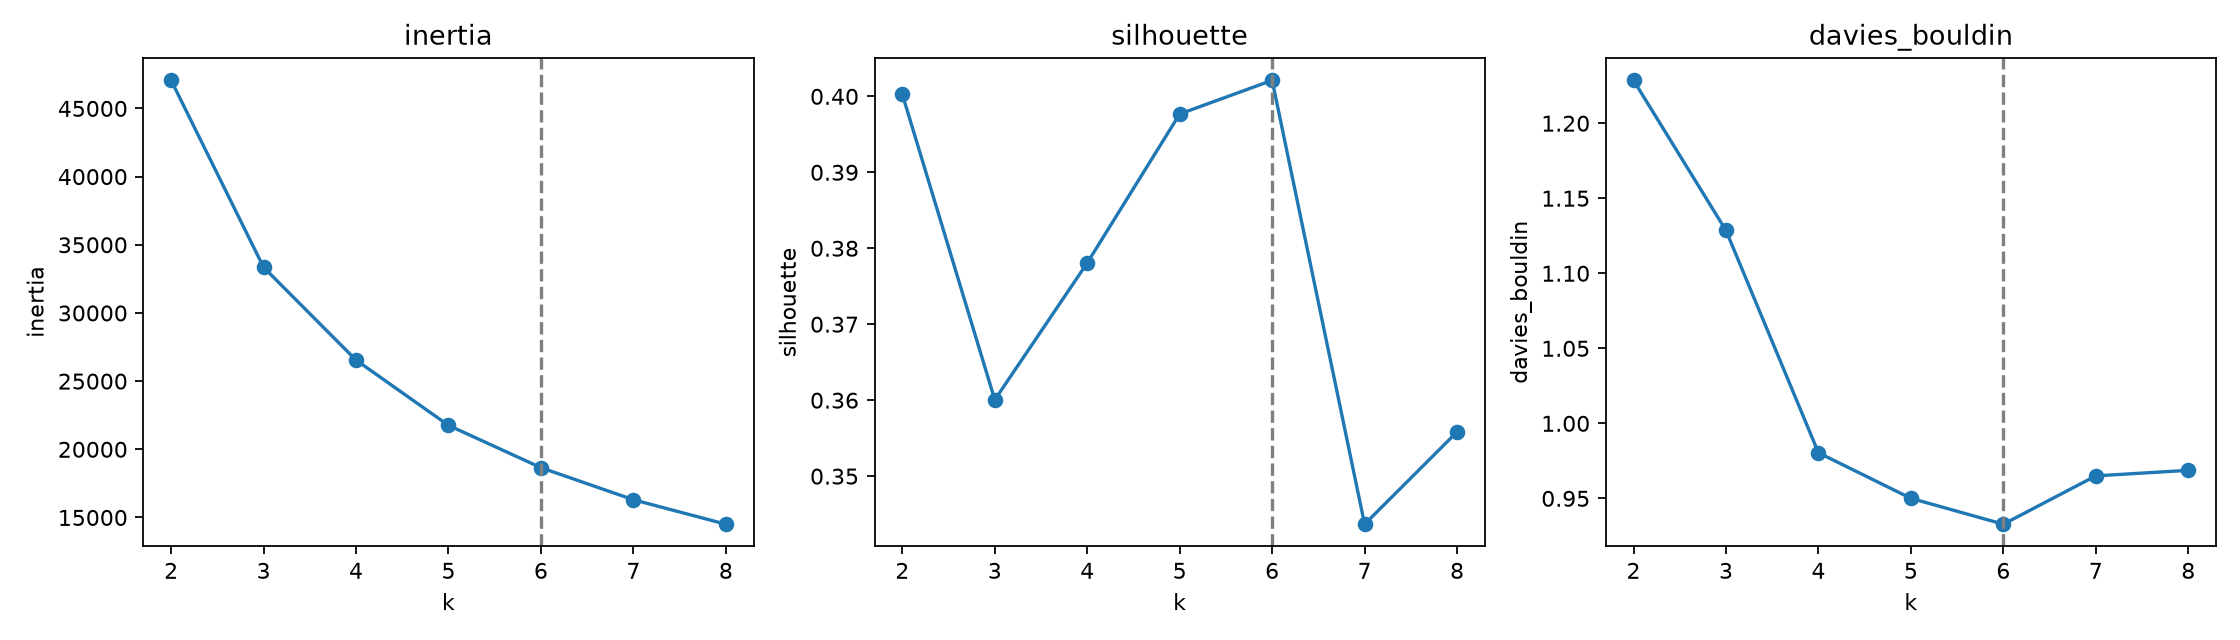

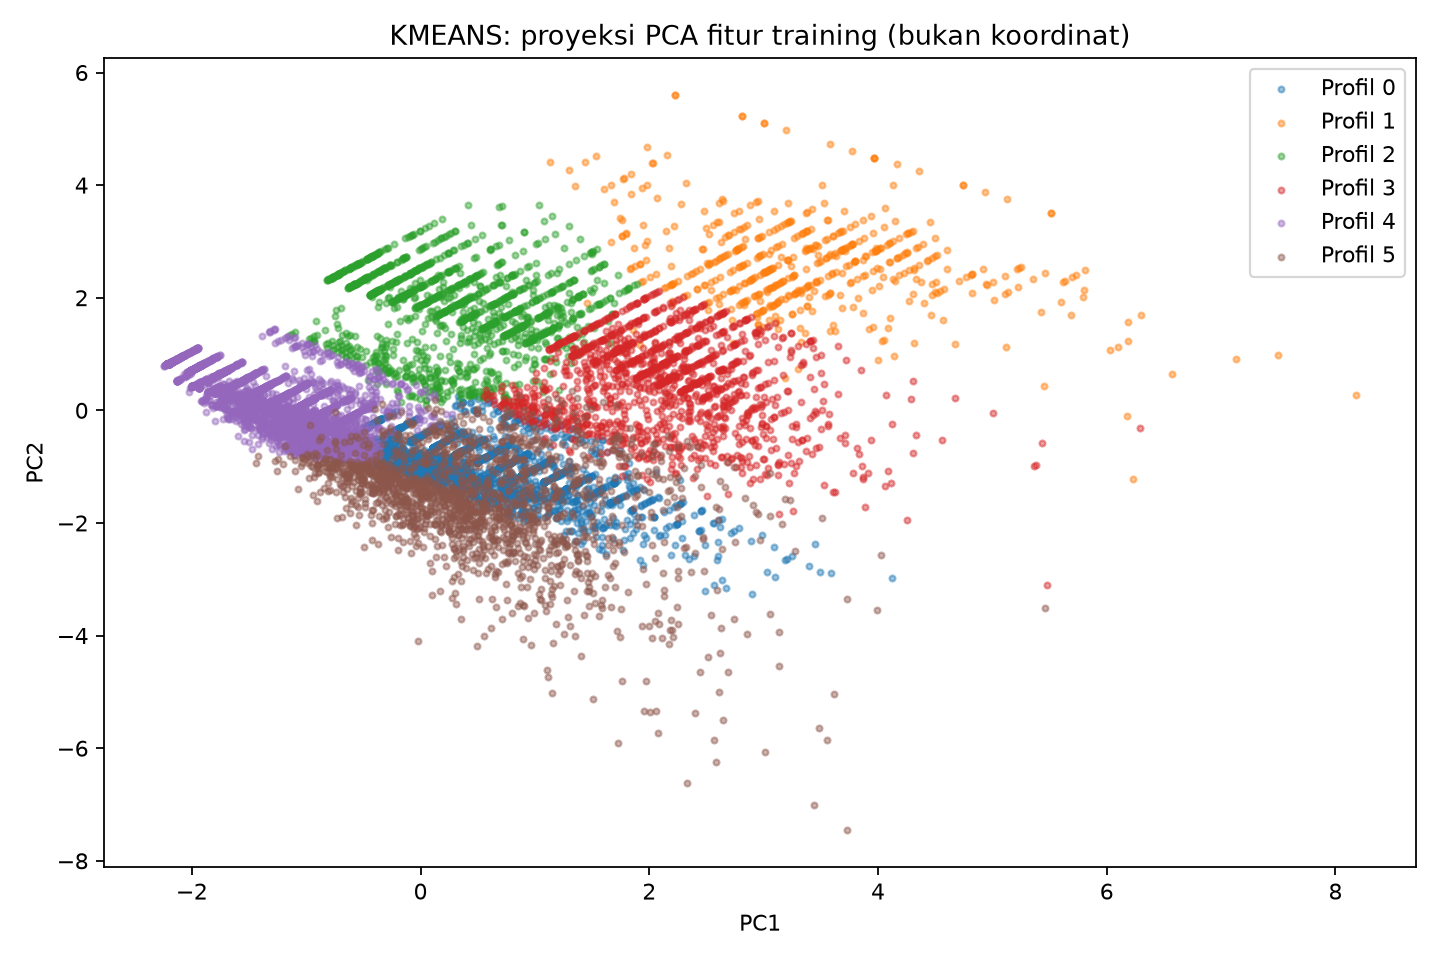

profile
NO_EVENTS    21689
KMEANS_P4     5528
KMEANS_P0     2895
KMEANS_P5     1757
KMEANS_P3     1407
KMEANS_P2     1348
KMEANS_P1      536
Name: n_grid_quarters, dtype: int64

In [8]:
display(Image(filename=str(ROOT / "reports/figures/kmeans_selection.png")))
display(Image(filename=str(ROOT / "reports/figures/kmeans_pca.png")))
display(labels["profile"].value_counts().rename("n_grid_quarters"))

## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.